In [1]:
import os

import torch
from torch.utils.data import DataLoader, Subset

from torchvision.datasets import ImageFolder
from torchvision import transforms

import matplotlib.pyplot as plt
import numpy as np

In [2]:
ruta_dataset = "../dataset_cat"

In [3]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [4]:
dataset = ImageFolder(
    root=ruta_dataset,
    transform=transform
)

In [5]:
print("Número de imágenes:", len(dataset))
print("Clases:", dataset.classes)
print("Etiquetas:", dataset.class_to_idx)

Número de imágenes: 1613
Clases: ['Abyssinian', 'Bengal', 'Bombay', 'British Shorthair', 'Egyptian Mau', 'Maine Coon', 'Persian', 'Ragdoll', 'Siamese', 'Sphynx']
Etiquetas: {'Abyssinian': 0, 'Bengal': 1, 'Bombay': 2, 'British Shorthair': 3, 'Egyptian Mau': 4, 'Maine Coon': 5, 'Persian': 6, 'Ragdoll': 7, 'Siamese': 8, 'Sphynx': 9}


In [8]:
imagen, etiqueta = dataset[0]

print("Forma del tensor:", imagen.shape)
print("Etiqueta numérica:", etiqueta)
print("Clase:", dataset.classes[etiqueta])

Forma del tensor: torch.Size([3, 128, 128])
Etiqueta numérica: 0
Clase: Abyssinian


In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

In [7]:
indices = np.arange(len(dataset))
etiquetas = dataset.targets

indices_train, indices_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=42
)

indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[indices_temp],
    random_state=42
)

In [8]:
train_dataset = Subset(dataset, indices_train)
val_dataset = Subset(dataset, indices_val)
test_dataset = Subset(dataset, indices_test)

In [12]:
print("Entrenamiento:", len(train_dataset))
print("Validación:", len(val_dataset))
print("Test:", len(test_dataset))

Entrenamiento: 1129
Validación: 242
Test: 242


In [9]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [14]:
for imagenes, etiquetas in train_loader:
    print("Forma imágenes:", imagenes.shape)
    print("Forma etiquetas:", etiquetas.shape)
    print("Etiquetas:", etiquetas)
    break

Forma imágenes: torch.Size([32, 3, 128, 128])
Forma etiquetas: torch.Size([32])
Etiquetas: tensor([4, 8, 1, 0, 7, 7, 7, 1, 6, 4, 0, 9, 2, 2, 6, 3, 6, 2, 8, 3, 9, 7, 7, 7,
        9, 5, 9, 4, 1, 7, 5, 8])


In [10]:
import torch.nn as nn
import torch.nn.functional as F

In [11]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(32 * 32 * 32, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [12]:
model = CNN()

print(model)

CNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=32768, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [13]:
imagenes, etiquetas = next(iter(train_loader))

salidas = model(imagenes)

print("Entrada:", imagenes.shape)
print("Salida:", salidas.shape)

Entrada: torch.Size([32, 3, 128, 128])
Salida: torch.Size([32, 10])


In [14]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for imagenes, etiquetas in train_loader:

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    loss_epoch = running_loss / len(train_loader)

    print(
        f"Época {epoch + 1}/{num_epochs} - "
        f"Loss: {loss_epoch:.4f}"
    )

Época 1/5 - Loss: 2.2695
Época 2/5 - Loss: 1.9805
Época 3/5 - Loss: 1.7215
Época 4/5 - Loss: 1.6176
Época 5/5 - Loss: 1.3205


In [21]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self, dropout=0.5):
        super(CNN, self).__init__()

        # Bloque convolucional 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # Bloque convolucional 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Bloque convolucional 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.global_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)

        return x


Dispositivo: cpu
CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Época 01/35 | Train Loss: 2.2006 | Val Loss: 2.3113 | Train Acc: 20.90% | Val Acc: 13.64%
Época 02/35 | Train Loss: 1.9426 | Val Loss: 1.9645 | Train Acc: 29.85% | Val Ac

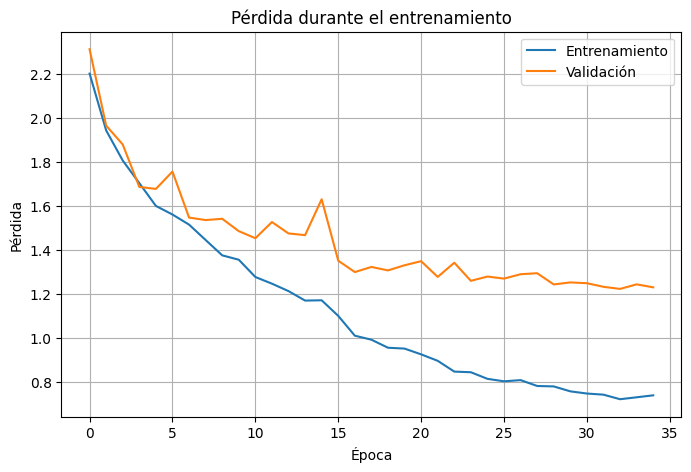

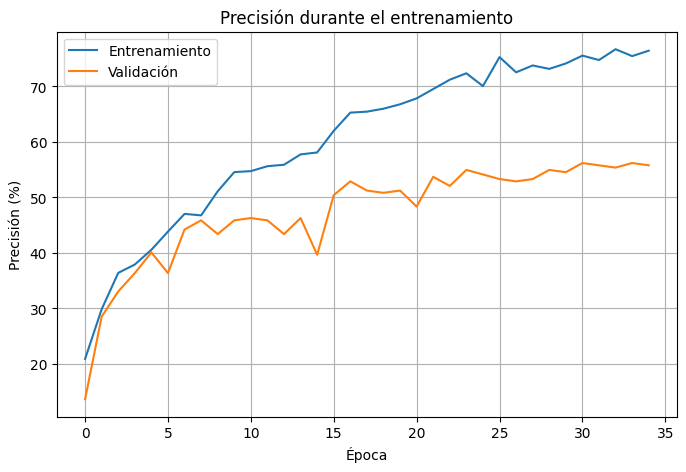

In [22]:

import copy
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# =========================================
# 1. CONFIGURACIÓN
# =========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

max_epochs = 35
patience = 8
min_delta = 0.001

# =========================================
# 2. CREAR MODELO Y OPTIMIZADOR
# =========================================
model = CNN(dropout=0.5).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print(model)

# =========================================
# 3. VARIABLES DE SEGUIMIENTO
# =========================================
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
best_weights = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

start_time = time.time()

# =========================================
# 4. BUCLE DE ENTRENAMIENTO
# =========================================
for epoch in range(max_epochs):

    # ---------- ENTRENAMIENTO ----------
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # ---------- VALIDACIÓN ----------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = 100.0 * val_correct / val_total

    # Ajustar tasa de aprendizaje
    scheduler.step(val_loss)

    # Guardar métricas
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Época {epoch + 1:02d}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

    # ---------- EARLY STOPPING ----------
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

        torch.save(best_weights, "mejor_modelo_gatos.pth")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping en la época {epoch + 1}.")
        break

# =========================================
# 5. RESTAURAR MEJORES PESOS
# =========================================
model.load_state_dict(best_weights)

elapsed = (time.time() - start_time) / 60

print("\nEntrenamiento terminado.")
print("Mejor época:", best_epoch)
print(f"Mejor pérdida de validación: {best_val_loss:.4f}")
print(f"Precisión de validación en esa época: {best_val_acc:.2f}%")
print(f"Tiempo total: {elapsed:.2f} minutos")

# =========================================
# 6. GRÁFICAS
# =========================================
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Entrenamiento")
plt.plot(val_losses, label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento")
plt.legend()
plt.grid(True)
plt.savefig("perdida_gatos.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, label="Entrenamiento")
plt.plot(val_accuracies, label="Validación")
plt.xlabel("Época")
plt.ylabel("Precisión (%)")
plt.title("Precisión durante el entrenamiento")
plt.legend()
plt.grid(True)
plt.savefig("precision_gatos.png", dpi=150, bbox_inches="tight")
plt.show()
